<a href="https://colab.research.google.com/github/mf1060/ml-2026/blob/main/HW5/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Michael Furey

Dr. Forouraghi

HW #5

October 26, 2026

# Introduction

The following is an analysis of a diabetes dataset with the machine learning repository at UC Irvine. A copy of this dataset can be found [here](https://raw.githubusercontent.com/LamaHamadeh/Pima-Indians-Diabetes-DataSet-UCI/refs/heads/master/pima_indians_diabetes.txt). This notebook uses methods and documentation from two notebooks: (1) [06_ensemble_learning_and_random_forests.ipynb](https://github.com/bforoura/ML26/blob/main/Module6_Ensemble_RF/06_ensemble_learning_and_random_forests.ipynb) and [wine_recognition.ipynb](https://github.com/bforoura/ML26/blob/main/Module6_Ensemble_RF/wine_recognition.ipynb). The goal of this assignment is to use ensemble learning methods from these notebooks to classify diabetes risk.

This notebook uses code and methods from the class [End-to-End Machine Learning Project](https://github.com/bforoura/ML26/blob/main/Module2_ML_Projects/02_end_to_end_machine_learning_project.ipynb) and makes reference to our textbook (Aurélien Géron, Hands-On Machine Learning with SciKit-Learn and PyTorch (2025)) as well as the Chapter 7 overview.

# Task 1: Loading the Dataset

Here, we load the dataset from a copy on Github. We can see that there is about a 60% - 30% division in the target variable.

In [1]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

# # Loading the dataset from UCI: https://raw.githubusercontent.com/LamaHamadeh/Pima-Indians-Diabetes-DataSet-UCI/refs/heads/master/pima_indians_diabetes.txt
diabetes = pd.read_csv("https://raw.githubusercontent.com/LamaHamadeh/Pima-Indians-Diabetes-DataSet-UCI/refs/heads/master/pima_indians_diabetes.txt",
                            names=['months_pregnant', 'plasma_glucose', 'blood_pressure', 'skin_thickness',
             'serum_insulin', 'bmi', 'diabetes_pedigree_function', 'age', 'class'])

# data (as pandas dataframes)
# Designating the features and target variables from this dataset, as X and y, respectively.
# Using the columns from: https://github.com/LamaHamadeh/Pima-Indians-Diabetes-DataSet-UCI/blob/master/prima_indians_diabetes.py
X = diabetes[['months_pregnant', 'plasma_glucose', 'blood_pressure', 'skin_thickness',
             'serum_insulin', 'bmi', 'diabetes_pedigree_function', 'age']]
#Setting a variable for the original targets
y = diabetes['class']

# Split the data into training and testing sets with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print(f"Class distribution in y_train:\n{y_train.value_counts(normalize=True)}")

Training set shape: (614, 8)
Testing set shape: (154, 8)
Class distribution in y_train:
class
0    0.651466
1    0.348534
Name: proportion, dtype: float64


# Task 2: Inspecting the Dataframe

When using methods such as `.info()` and `.describe()`, we can see that all of these columns appear to be numeric. We are told that some values have implicit zeros, which need to be replaced. However, legitimate zeros (such as the feature, `months_pregnant`) should not be replaced.

In [2]:
# Display the first 5 rows
display(y.head())

# Print concise summary of columns, non-null counts, and data types
print("\nDataset Information:")
display(y.info())
display(y.describe())

# Display the first 5 rows
display(X.head())

# Print concise summary of columns, non-null counts, and data types
print("\nDataset Information:")
display(X.info())
display(X.describe())

,class
0,1
1,0
2,1
3,0
4,1



Dataset Information:
<class 'pandas.core.series.Series'>
RangeIndex: 768 entries, 0 to 767
Series name: class
Non-Null Count  Dtype
--------------  -----
768 non-null    int64
dtypes: int64(1)
memory usage: 6.1 KB


None

,class
count,768.000000
mean,0.348958
std,0.476951
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


,months_pregnant,plasma_glucose,blood_pressure,skin_thickness,serum_insulin,bmi,diabetes_pedigree_function,age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   months_pregnant             768 non-null    int64  
 1   plasma_glucose              768 non-null    int64  
 2   blood_pressure              768 non-null    int64  
 3   skin_thickness              768 non-null    int64  
 4   serum_insulin               768 non-null    int64  
 5   bmi                         768 non-null    float64
 6   diabetes_pedigree_function  768 non-null    float64
 7   age                         768 non-null    int64  
dtypes: float64(2), int64(6)
memory usage: 48.1 KB


None

,months_pregnant,plasma_glucose,blood_pressure,skin_thickness,serum_insulin,bmi,diabetes_pedigree_function,age
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000


We can see that the values with implicit zeros are all features except for variables `months_pregnant`, `diabetes_pedigree_function`, and `age`. We also see that features such as `serum_insulin`, `diabetes_pedigree_function` and `age` may require log-scaling as each have long tails in their distribution.

array([[<Axes: title={'center': 'months_pregnant'}>,
        <Axes: title={'center': 'plasma_glucose'}>,
        <Axes: title={'center': 'blood_pressure'}>],
       [<Axes: title={'center': 'skin_thickness'}>,
        <Axes: title={'center': 'serum_insulin'}>,
        <Axes: title={'center': 'bmi'}>],
       [<Axes: title={'center': 'diabetes_pedigree_function'}>,
        <Axes: title={'center': 'age'}>, <Axes: >]], dtype=object)

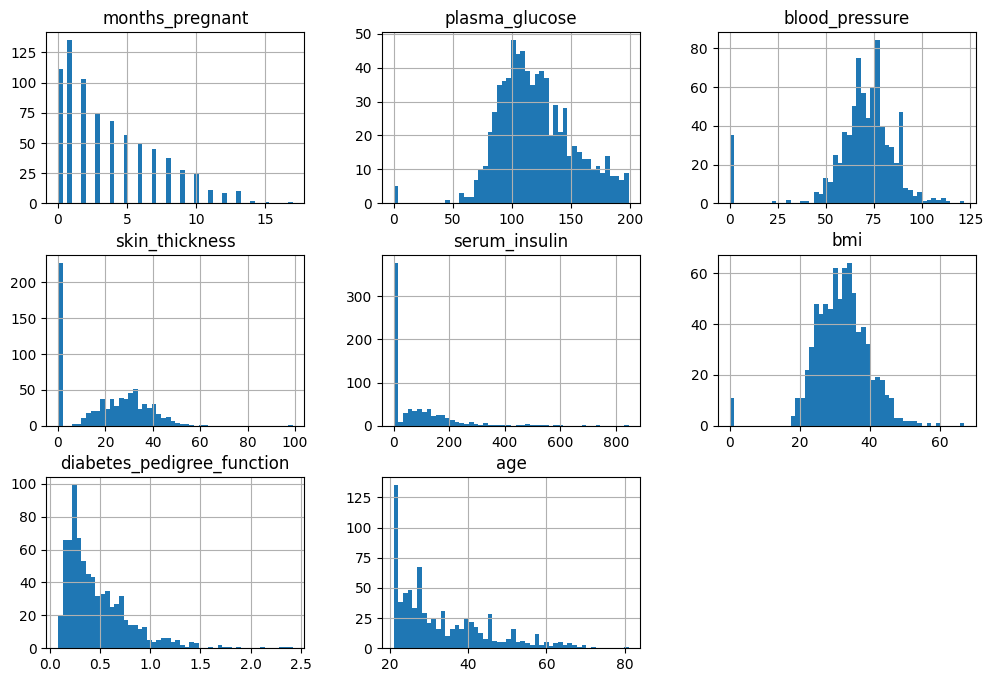

In [3]:
X.hist(bins=50, figsize=(12, 8))

# Task 3 and 4: Handling Missing Values and Building a Pipeline

According to its [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html), we can use the SimpleImputer and the parameter, `missing_values`, to fill in a median value for each missing zero.

Here, we also define pipelines for each ensemble learning model. The following uses methods from the [Spam, No Spam Classification Notebook](https://github.com/bforoura/ML26/blob/main/Module3_Classification/spam_nospam_sgdclassifier.ipynb) including its documentation to create pipelines.

In [4]:
#Importing the method for a pipeline
from sklearn.pipeline import Pipeline
#Importing a simple imputer for filling empty values
from sklearn.impute import SimpleImputer
#Importing a one hot encoder for creating dummy variables for categorical data
from sklearn.preprocessing import OneHotEncoder
#Importing libraries for creating pipelines and a transformer
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
#Importing a Standard Scaler to standardize values.
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import make_column_selector, make_column_transformer

#Importing SGD Classifier
from sklearn.linear_model import SGDClassifier

#Importing SVC
from sklearn.svm import SVC

# Using methods from "end-to-end machine learning project"
from sklearn.preprocessing import FunctionTransformer

#Importing libraries for Decision Trees, cross validation scoring,
# and creating a classification report
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report


# The following defines the pipeline for numeric values that imputes
# a median value and a standard scaler.
numeric_imputer_standard = Pipeline(steps=[
    #Replacing all implicit 0s with median value.
    #With reference to the Simple Imputer documentation: https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html
    ('imputer', SimpleImputer(missing_values=0, strategy='median')),
    ('scaler', StandardScaler())
])

# The following defines the pipeline for numeric values that imputes
# a median value and a standard scaler.
numeric_standard = Pipeline(steps=[
    #Replacing all implicit 0s with median value.
    #With reference to the Simple Imputer documentation: https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html
    ('scaler', StandardScaler())
])

# The following defines a pipeline for log-scaling values. We first impute the
#median for missing values, we apply a log function to each value, and then a
#standard scaler.

# Using methods from "end-to-end machine learning project"
# Using log scaling methods from pg. 160 of the full textbook linked to our class.
# Also Referencing a logtransformer method from: https://docs.kanaries.net/topics/Scikit-Learn/sklearn-pipeline
log_scaler_imputer_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(missing_values=0, strategy='median')),
    ('logger', FunctionTransformer(np.log))
])

log_scaler_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('logger', FunctionTransformer(np.log))
])

# Defining a ColumnTransformer for transforming both numeric and
# categorical features.

#Features with standard scaling, imputation
num_imputed_features = ['plasma_glucose', 'blood_pressure', 'skin_thickness', 'bmi']
#Standard scaling, no imputation
num_non_imputed_features = ['months_pregnant']
#Log scaling, imputation
log_imputed_features = ['serum_insulin']
#Log scaling, no imputation
log_non_imputed_features = ['age', 'diabetes_pedigree_function']

#Appling scaling to different columns
preprocessor_standard = ColumnTransformer(
    transformers=[
        ('num_imputed', numeric_imputer_standard, num_imputed_features),
        ('num_non_imputed', numeric_standard, num_non_imputed_features),
        ('log_imputed', log_scaler_imputer_pipeline, log_imputed_features),
        ('log_non_imputed', log_scaler_pipeline, log_non_imputed_features)
    ])

from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression

# Initialize distinct classification models
log_clf = LogisticRegression(random_state=42, max_iter=5000)
rnd_clf = RandomForestClassifier(n_estimators=100, random_state=42)
svm_clf = SVC(gamma="scale", probability=True, random_state=42)

# Defines a pipeline that uses a logistic regression classifier.
log_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_standard),
    # Initialize the Decision Tree Classifier with regularization parameters to prevent overfitting
    ('classifier', log_clf)
])

#Defines a pipeline that uses a random forest classifier with 100 different trees.
rnd_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_standard),
    # Initialize the Decision Tree Classifier with regularization parameters to prevent overfitting
    ('classifier', rnd_clf)
])

#Defines a pipeline that uses a support vector machine classifier.
svm_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_standard),
    # Initialize the Decision Tree Classifier with regularization parameters to prevent overfitting
    ('classifier', svm_clf)
])

# Create a soft voting classifier combining the three estimators
voting_clf_soft = VotingClassifier(
    estimators=[("lr", log_clf), ("rf", rnd_clf), ("svc", svm_clf)],
    voting="soft",
)

# Creates a soft voting pipeline that includes the preprocessor and the soft voting classifier.
voting_clf_soft_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_standard),
    # Initialize the Decision Tree Classifier with regularization parameters to prevent overfitting
    ('classifier', voting_clf_soft)
])

# Creates a hard voting pipeline that includes the preprocessor and the hard voting classifier.
voting_clf_hard = VotingClassifier(
    estimators=[("lr", log_clf), ("rf", rnd_clf), ("svc", svm_clf)],
    voting="hard",
)

# Creates a soft voting pipeline that includes the preprocessor and the hard voting classifier.
voting_clf_hard_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_standard),
    # Initialize the Decision Tree Classifier with regularization parameters to prevent overfitting
    ('classifier', voting_clf_hard)
])

# Importing libraries for the bagging classifier
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

#Creates a bagging classifier that uses the DecisionTree Classifier with 500 estimators and 100 samples.
#With reference to: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html
bag_clf = BaggingClassifier(DecisionTreeClassifier(), n_estimators=500,
                            max_samples=100, n_jobs=-1, random_state=42)

#Combines the bagging classifier with the preprocessor in a single pipeline.
bag_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_standard),
    # Initialize the Decision Tree Classifier with regularization parameters to prevent overfitting
    ('classifier', bag_clf)
])

# Out-of-Bag Model
# Enables the oob_score to include out of bag estimates in the error rate.
# With reference to: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html
bag_clf_oob = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=500,
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=42,
)

#Combines the out-of-bag classifier with the preprocessor in a single pipeline.
bag_oob_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_standard),
    # Initialize the Decision Tree Classifier with regularization parameters to prevent overfitting
    ('classifier', bag_clf_oob)
])

# Random Forest Classifier
# Defines a Random Forest classifier that subsets features with a square root
# With reference to: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
rand_for_clf = RandomForestClassifier(
    n_estimators=500, max_features="sqrt", random_state=42, n_jobs=-1
)

# Combines the random forest classifier with the preprocessor in a single pipeline.
rand_for_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_standard),
    # Initialize the Decision Tree Classifier with regularization parameters to prevent overfitting
    ('classifier', rand_for_clf)
])

# Ada Boost Classifier

from sklearn.ensemble import AdaBoostClassifier

# Defines an ADA Boost classifier with 200 stumps and an algorithm that uses probabilities
# With reference to the Chapter 7 overview.
# With reference to: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html
ada_clf = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=200,
    algorithm="SAMME",
    learning_rate=0.5,
    random_state=42,
)

# Creates a pipeline that combines the ADA Boost and the preprocessor pipeline.
ada_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_standard),
    # Initialize the Decision Tree Classifier with regularization parameters to prevent overfitting
    ('classifier', ada_clf)
])

# Task 5: Comparing Hard and Soft Voting Classification

The following compares the results of a hard voting and soft voting classifier with three different models: logistic regression, decision tree, and support vector machine (SVM). We can see that the hard voting classifier performs better than the soft voting classifier. However, the SVM classifier performs slightly better.

Logistic Regression       Accuracy: 0.7344
Random Forest             Accuracy: 0.7396
SVM                       Accuracy: 0.7552
Soft Voting               Accuracy: 0.7396
Hard Voting               Accuracy: 0.7448


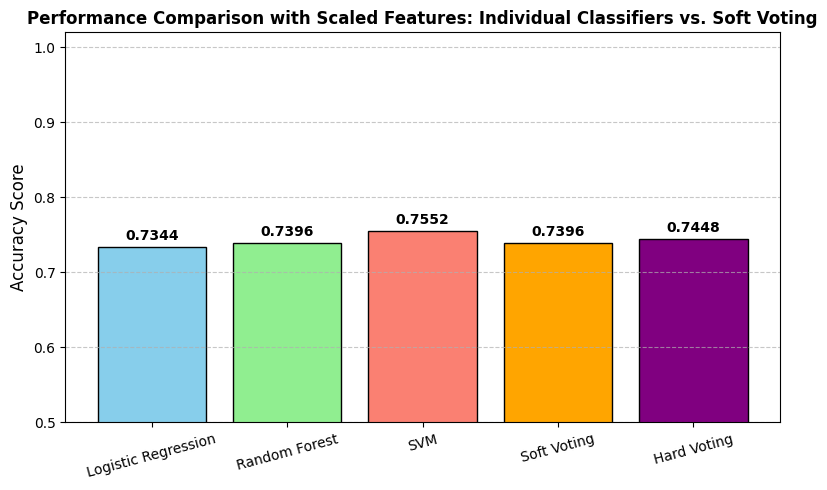

In [5]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Load dataset and split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=42
)
# Creates a dictionary of the models to create the graph.
models = {
    "Logistic Regression": log_pipeline,
    "Random Forest": rnd_pipeline,
    "SVM": svm_pipeline,
    "Soft Voting": voting_clf_soft_pipeline,
    "Hard Voting": voting_clf_hard_pipeline
}

names = []
accuracies = []

# Train and evaluate each model on scaled data
for name, clf in models.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    names.append(name)
    accuracies.append(acc)
    print(f"{name:<25} Accuracy: {acc:.4f}")

# Create the bar plot
plt.figure(figsize=(8, 5))
bars = plt.bar(
    names,
    accuracies,
    color=["skyblue", "lightgreen", "salmon", "orange", "purple"],
    edgecolor="black",
)
plt.ylabel("Accuracy Score", fontsize=12)
plt.title(
    "Performance Comparison with Scaled Features: Individual Classifiers vs. Soft Voting",
    fontsize=12,
    fontweight="bold",
)
plt.ylim(0.5, 1.02)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Annotate accuracy values on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.005,
        f"{yval:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.xticks(rotation=15, fontsize=10)
plt.tight_layout()
plt.show()

# Task 6 Out of Bag Comparison

When including the out of bag estimates, we see that the model performs slightly better than the test set alone. Out of bag estimates are helpful for evaluating the model on instances that were not included. According to Module 7 overview and the [Wine Recognition Notebook](https://github.com/bforoura/ML26/blob/main/Module6_Ensemble_RF/wine_recognition.ipynb), when the out of bag estimate performs as well (or in this case better) than the test accuracy, we do not need a separate cross-validation.

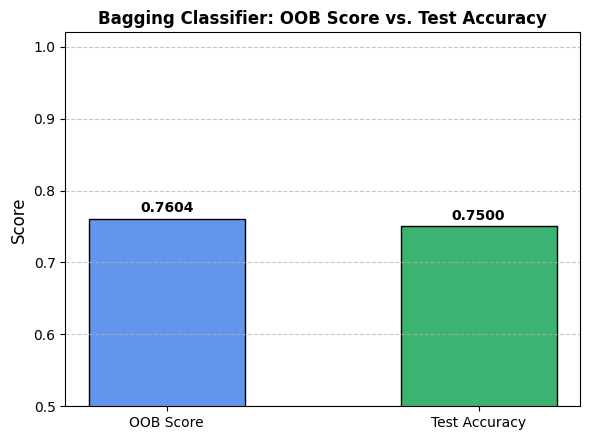

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=42
)

# Fit the bagging classifier on the training data
bag_clf = bag_oob_pipeline.fit(X_train, y_train)

# Evaluate on the test set
y_pred = bag_clf.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)

# Prepare data for plotting
metrics = ["OOB Score", "Test Accuracy"]
scores = [bag_clf.named_steps['classifier'].oob_score_, test_accuracy]

# Create the bar plot
plt.figure(figsize=(6, 4.5))
bars = plt.bar(
    metrics,
    scores,
    color=["cornflowerblue", "mediumseagreen"],
    edgecolor="black",
    width=0.5,
)
plt.ylabel("Score", fontsize=12)
plt.title(
    "Bagging Classifier: OOB Score vs. Test Accuracy",
    fontsize=12,
    fontweight="bold",
)
plt.ylim(0.5, 1.02)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Annotate accuracy values on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.005,
        f"{yval:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

# Task 7: Random Forest Feature Importance

The following uses a Random Forest classifier to rank feature importance by decreasing impurity. We can see that `months_pregnant`, `skin_thickness`, `diabetes_pedigree_function` and `age` are significant features.

Random Forest Test Accuracy: 0.7656

Classification Report:
              precision    recall  f1-score   support

  class_test       0.82      0.80      0.81       123
  class_pred       0.67      0.70      0.68        69

    accuracy                           0.77       192
   macro avg       0.75      0.75      0.75       192
weighted avg       0.77      0.77      0.77       192



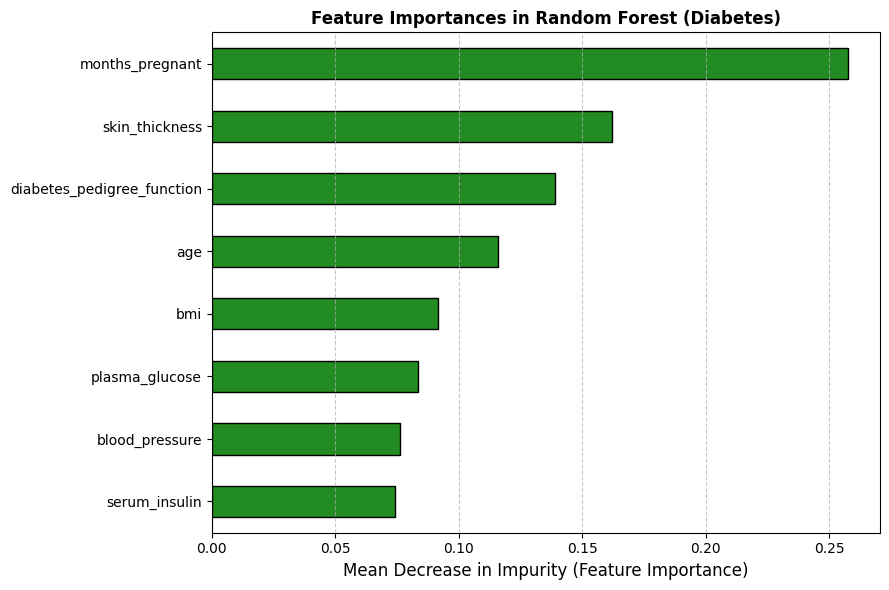

In [7]:
# Load dataset and split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=42
)

# Training the random forest model
rf_clf = rand_for_pipeline.fit(X_train, y_train)

# Evaluate on the test set
y_pred = rf_clf.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Random Forest Test Accuracy: {test_accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['class_test', 'class_pred']))

X_columns = ['months_pregnant', 'plasma_glucose', 'blood_pressure', 'skin_thickness',
             'serum_insulin', 'bmi', 'diabetes_pedigree_function', 'age']

# Extract and display feature importances
importances = pd.Series(rf_clf.named_steps['classifier'].feature_importances_, index=X_columns)
importances_sorted = importances.sort_values(ascending=True)

# Plot feature importances
plt.figure(figsize=(9, 6))
importances_sorted.plot(kind="barh", color="forestgreen", edgecolor="black")
plt.xlabel("Mean Decrease in Impurity (Feature Importance)", fontsize=12)
plt.title(
    "Feature Importances in Random Forest (Diabetes)",
    fontsize=12,
    fontweight="bold",
)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

# Class 8: Ada Boosting

Here, we can see that the ADA Boost performs better than the test set. According to the Module 7 overview and the [Wine Recognition Notebook](https://github.com/bforoura/ML26/blob/main/Module6_Ensemble_RF/wine_recognition.ipynb) the ADA Boost runs successive classifiers by having the next classifier pay closer attention to weaker estimates in the previous classifier. We can also see that although ADA Boost performs better than all the other classifiers in this notebook, it does not appear to overfit the data. The discrepancy between the training and test accuracy is not so large and the ADA Boost does not fit each sample perfectly.

/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(


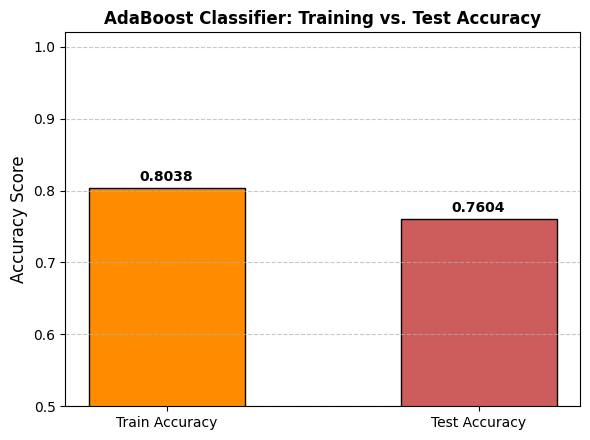

In [8]:
# Load dataset and split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=42
)

# Train the model
ada_clf = ada_pipeline.fit(X_train, y_train)

# Evaluate accuracies
train_accuracy = accuracy_score(y_train, ada_clf.predict(X_train))
test_accuracy = accuracy_score(y_test, ada_clf.predict(X_test))

# Prepare data for plotting
metrics = ["Train Accuracy", "Test Accuracy"]
scores = [train_accuracy, test_accuracy]

# Create the bar plot
plt.figure(figsize=(6, 4.5))
bars = plt.bar(
    metrics,
    scores,
    color=["darkorange", "indianred"],
    edgecolor="black",
    width=0.5,
)
plt.ylabel("Accuracy Score", fontsize=12)
plt.title(
    "AdaBoost Classifier: Training vs. Test Accuracy",
    fontsize=12,
    fontweight="bold",
)
plt.ylim(0.5, 1.02)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Annotate accuracy values on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.005,
        f"{yval:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()